In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
from sklearn.metrics import r2_score

from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot
from statistics_functions import chi_squared

In [2]:
data, var = load_data_and_var()

In [3]:
10**(-27.2)

6.309573444801942e-28

In [4]:
np.max(data['E_MSZ']/data['MSZ'])

0.16178727616706906

In [5]:
np.max(data['e_MSZ']/data['MSZ'])

0.1975252719463472

In [6]:
np.max(data['E_MSZ'])

0.536452

In [7]:
np.max(data['e_MSZ'])

0.579554

(array([43., 73., 36.,  6.,  4.,  6.,  1.,  2.,  0.,  2.]),
 array([0.01626278, 0.07351638, 0.13076998, 0.18802358, 0.24527717,
        0.30253077, 0.35978437, 0.41703796, 0.47429156, 0.53154516,
        0.58879876]),
 <BarContainer object of 10 artists>)

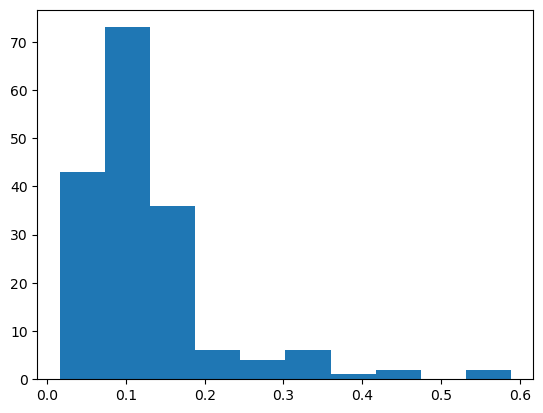

In [8]:
plt.hist(data['L_err']/data['L500'])

In [9]:
np.max(data['L_err']/data['L500'])

0.5887987557167547

In [10]:
cold_nfw_row = data.iloc[73]
cold_nfw_row, var[73]

(MCXC          J1038.4-2454
 OName      RXCJ1038.4-2454
 L500              1.500662
 Sub-Cat             REFLEX
 RXC        RXCJ1038.4-2454
 Flux                 4.134
 e_Flux                13.5
 ObsLum               1.545
 LumCor               1.661
 z_x                  0.123
 z_y                  0.123
 MSZ               2.832914
 E_MSZ             0.329354
 e_MSZ             0.336738
 L_err             0.170556
 Name: 98, dtype: object,
 <Quantity 0.17055621 1e+44 erg / s>)

In [11]:
nfws_full=generate_nfws_from_combined_dataset_werr(data, var)

In [12]:
nfws = [nfw for nfw in nfws_full if nfw.z < 0.2]

In [13]:
nfws_subset = [nfw for nfw in nfws if nfw.energies.is_virialized_gaspari ]
zs = [nfw.z for nfw in nfws_subset]
filtered_vir = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_subset]

len(nfws_subset)

111

In [14]:
nfws_not_virialized = [nfw for nfw in nfws if not nfw.energies.is_virialized_gaspari]
zs_not_virialized = [nfw.z for nfw in nfws_not_virialized]
fractions_not_virialized = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_not_virialized]

In [15]:
# Function to calculate weighted R^2 with asymmetric errors
def calculate_weighted_r2_asymmetric(y_actual, y_predicted, y_errors_neg, y_errors_pos):
    y_errors_avg = (y_errors_neg + y_errors_pos) / 2
    weights = 1 / (y_errors_avg ** 2)
    weighted_mean = np.average(y_actual, weights=weights)
    print(weighted_mean)
    ss_tot = np.sum(weights * (y_actual - weighted_mean) ** 2)
    print(ss_tot)
    ss_res = np.sum(weights * (y_actual - y_predicted) ** 2)
    print(ss_res)
    r2 = 1 - (ss_res / ss_tot)
    return r2

In [16]:
y_pred_1 = np.ones_like(zs)
y_actual = np.array([f.value for f in filtered_vir])
y_errors_neg = np.array([v.minus for v in filtered_vir])
y_errors_pos = np.array([v.plus for v in filtered_vir])
r2_virialization = calculate_weighted_r2_asymmetric(y_actual, y_pred_1, y_errors_neg, y_errors_pos)
r2_virialization

0.9088432959577407
59.5875876243643
116.67014810586174


-0.9579605880563857

In [17]:
variance = (y_errors_neg + y_errors_pos)/2
virialization_chi_squared = chi_squared(y_pred_1, y_actual, variance, add_var=0)/len(y_actual)
virialization_chi_squared

1.051082415368124

In [41]:
paper_plot()
import matplotlib as mpl
mpl.rcParams['text.usetex'] = True

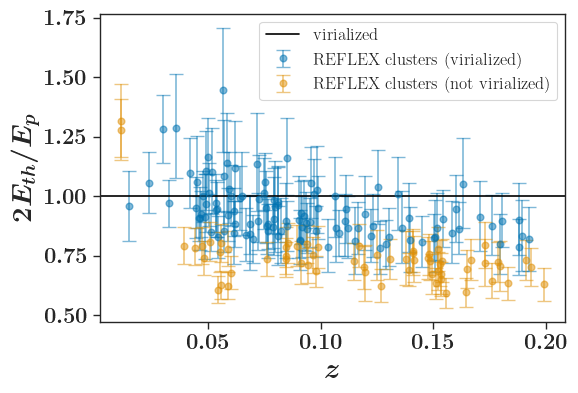

In [42]:

fig = plt.figure()
plt.errorbar(zs, filtered_vir,
             yerr=[[v.minus for v in filtered_vir],[v.plus for v in filtered_vir]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label='REFLEX clusters (virialized)')

plt.errorbar(zs_not_virialized, fractions_not_virialized,
             yerr=[[v.minus for v in fractions_not_virialized],[v.plus for v in fractions_not_virialized]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label='REFLEX clusters (not virialized)')

plt.axhline(1.0, color='black', label='virialized')

plt.xlabel(f'$z$')
plt.ylabel(f'$2E_{{th}}/E_{{p}}$')
plt.legend()

In [43]:
nfws_virialized_allz = [nfw for nfw in nfws_full if nfw.energies.is_virialized_gaspari ]
zs_virialized = [nfw.z for nfw in nfws_virialized_allz]
fraction_virialized_allz = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_virialized_allz]

len(nfws_virialized_allz)

111

In [44]:
nfws_not_vir_allz = [nfw for nfw in nfws_full if not nfw.energies.is_virialized_gaspari ]
zs_not_vir = [nfw.z for nfw in nfws_not_vir_allz]
fraction_virialized_allz = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_not_vir_allz]

len(nfws_not_vir_allz) # allz does not actually give all z because when i make the dataset i exclude by z in an earlier step

62

In [45]:
#savefig(fig,'plots/virialization.png') 

In [46]:
heating_rates = np.array([nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500) for nfw in nfws_subset])

In [47]:
cooling_rates = np.array([nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500, vol_rate='gfe') for nfw in nfws_subset])

In [48]:
len(nfws_subset)

111

In [49]:
max_index = np.argmax(cooling_rates)
max_index

73

In [50]:
cold_nfw = nfws_subset[73]
cold_nfw.total_heating_rate(0.001*cold_nfw.R500, cold_nfw.R500, 0.1*cold_nfw.R500)/1e44

In [51]:
cold_nfw.total_cooling_rate(0.001*cold_nfw.R500, cold_nfw.R500, vol_rate='gfe')/1e44

In [52]:
print(cold_nfw.M500, cold_nfw.L500)

509226399999999.94 (+35620699999999.99, -36664999999999.99) 9.458634 ± 0.9693479406374533


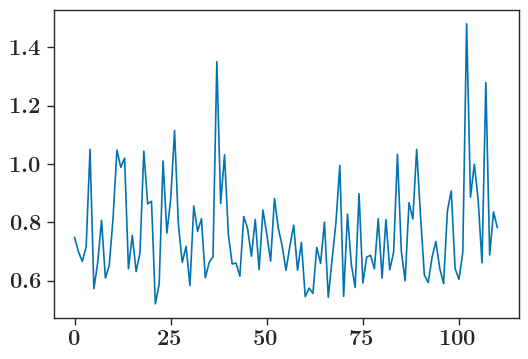

In [53]:
plt.plot(np.divide(heating_rates, cooling_rates))

(array([ 1.,  5., 23., 31., 22., 14.,  8.,  6.,  0.,  1.]),
 array([ 1.23711852,  2.15661831,  3.07611809,  3.99561787,  4.91511765,
         5.83461744,  6.75411722,  7.673617  ,  8.59311678,  9.51261657,
        10.43211635]),
 <BarContainer object of 10 artists>)

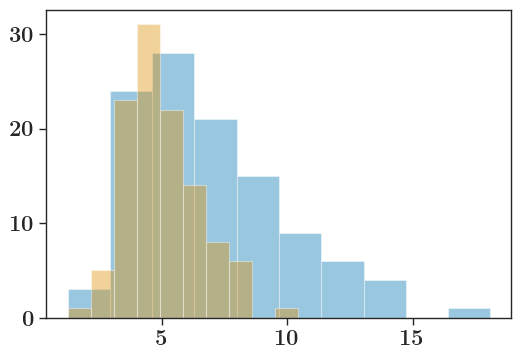

In [54]:
plt.hist([c.value for c in cooling_rates/1e44], alpha=0.4, bins=10)
plt.hist([h.value for h in heating_rates/1e44], alpha=0.4, bins=10)


In [55]:
def calculate_weighted_r2_asymmetric_both(y_actual, y_predicted, y_errors_neg, y_errors_pos, y_pred_errors_neg, y_pred_errors_pos):
    y_errors_avg = (y_errors_neg + y_errors_pos) / 2
    y_pred_errors_avg = (y_pred_errors_neg + y_pred_errors_pos) / 2
    combined_errors = np.sqrt(y_errors_avg**2 + y_pred_errors_avg**2)
    weights = 1 / (combined_errors ** 2)
    weighted_mean = np.average(y_actual, weights=weights)
    print(weighted_mean)
    ss_tot = np.sum(weights * (y_actual - weighted_mean) ** 2)
    ss_res = np.sum(weights * (y_actual - y_predicted) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return r2

Text(0.5, 0, 'heating rate/cooling rate')

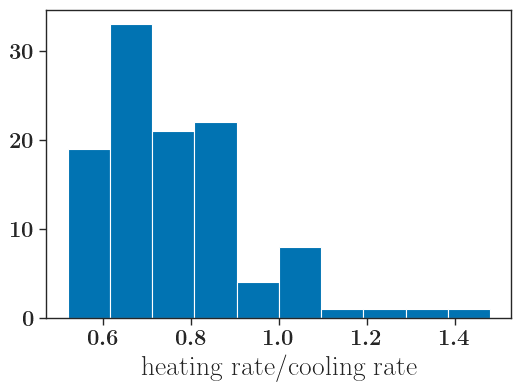

In [56]:
plt.hist(np.divide([h.value for h in heating_rates/1e44],[c.value for c in cooling_rates/1e44] ))
plt.xlabel('heating rate/cooling rate')

In [57]:
y_pred_rad = np.array([c.value for c in cooling_rates/1e44])
y_actual = np.array([h.value for h in heating_rates/1e44])
y_errors_neg = np.array([h.minus for h in heating_rates/1e44])
y_errors_pos = np.array([h.plus for h in heating_rates/1e44])

y_pred_errors_neg = np.array([c.minus for c in cooling_rates/1e44])
y_pred_errors_pos = np.array([c.plus for c in cooling_rates/1e44])
#r2_virialization = calculate_weighted_r2_asymmetric_both(y_actual, y_pred_rad, y_errors_neg, y_errors_pos, y_pred_errors_neg, y_pred_errors_pos)
#r2_virialization

In [58]:
variance = (y_errors_neg + y_errors_pos)/2
add_var = (y_pred_errors_neg + y_pred_errors_pos)/2
equil_chi_squared = chi_squared(y_pred_rad, y_actual, variance, add_var=0)/len(y_actual)
equil_chi_squared

41.6169537867765

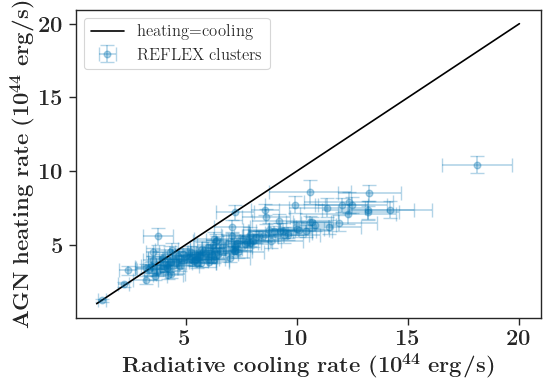

In [59]:
fig2 = plt.figure()
plt.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

plt.plot([1, 20], [1, 20], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.legend()

In [60]:
np.mean( heating_rates/1e44)

In [61]:
#savefig(fig2,'plots/heating_cooling.png') 

[]

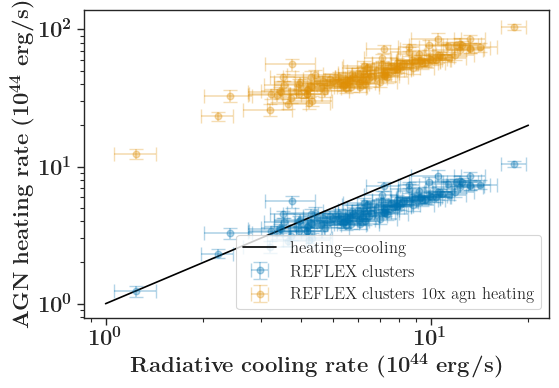

In [62]:
plt.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

plt.errorbar(cooling_rates/1e44, 10*heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in 10*heating_rates/1e44],[h.plus for h in 10*heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters 10x agn heating')

plt.plot([1, 20], [1, 20], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.legend()
plt.loglog()

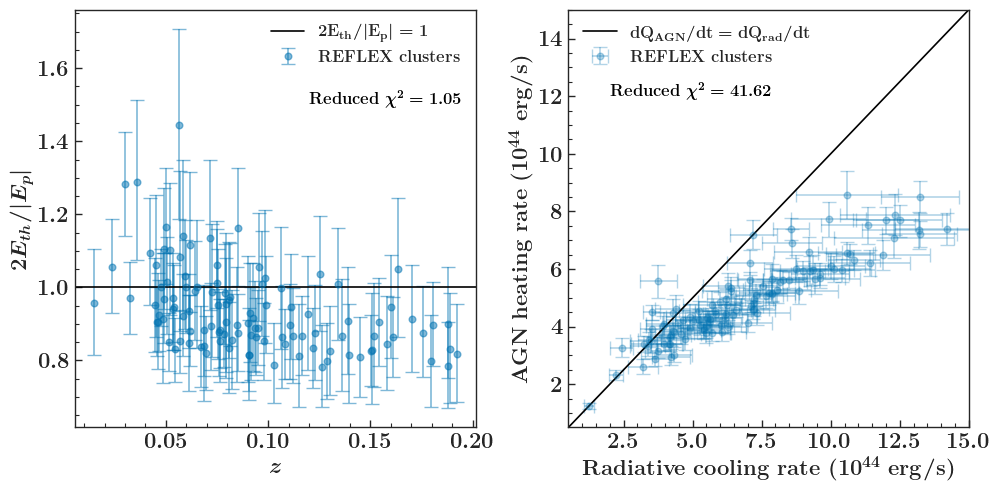

In [66]:
paper_plot()
#mpl.rcParams['text.usetex'] = False

subplotsfig, (ax1, ax2) =  plt.subplots(1, 2, figsize=(10, 5))

# First subplot
ax1.errorbar(zs, filtered_vir,
             yerr=[[v.minus for v in filtered_vir],[v.plus for v in filtered_vir]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label=f'$\mathrm{{REFLEX~clusters}}$')
ax1.axhline(1.0, color='black', label=f'$\mathrm{{2E_{{th}}/|E_{{p}}| = 1}}$')
ax1.legend(frameon=False)
#ax1.set_title('Plot 1')
ax1.set_xlabel(f'$z$', size=16)
ax1.set_ylabel(f'$2E_{{th}}/|E_{{p}}|$', size=16)
ax1.minorticks_on()  # Enable minor ticks
ax1.tick_params(which='both', direction='in')


ax1.text( 0.12, 1.5, f'$\mathrm{{Reduced~}}\chi^2 = {virialization_chi_squared:.2f}$', fontsize=12, color='black')


# Second subplot
ax2.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label=f'$\mathrm{{REFLEX~clusters}}$')


#plt.scatter(cold_nfw.total_cooling_rate(0.001*cold_nfw.R500, cold_nfw.R500, vol_rate='gfe')/1e44, cold_nfw.total_heating_rate(0.001*cold_nfw.R500, cold_nfw.R500, 0.1*cold_nfw.R500)/1e44, marker='*', s=100)

ax2.plot([0, 16], [0, 16], label='$\mathrm{{dQ_{AGN}}/{dt} = {dQ_{rad}}/{dt}}$', c='k')
plt.xlim(0.5, 15)
plt.ylim(0.5, 15)

ax2.set_ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.set_xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.legend(frameon=False)
ax2.minorticks_on()  # Enable minor ticks
ax2.tick_params(which='both', direction='in')



ax2.text(2, 12, f'$\mathrm{{Reduced~}}\chi^2 = {equil_chi_squared:.2f}$', fontsize=12, color='black')

#ax2.set_title('Plot 2')



plt.tight_layout()


In [67]:
savefig(subplotsfig,'plots/equilibrium_plots.png') 

2024-10-06T22:13:25.363256: made plots/equilibrium_plots.png


In [ ]:
equilibrium_clusters = []
eq_heating_rates = []
eq_cooling_rates = []
for n in nfws_subset:
    h = n.total_heating_rate(0.001*n.R500, n.R500, 0.1*n.R500)
    c = n.total_cooling_rate(0.001*n.R500, n.R500, vol_rate='gfe')
    #print(h.value-c.value, 2*h.plus, 2*h.minus, 2*c.plus, 2*c.minus)
    if (h.value - c.value) <= 2*h.minus or (h.value - c.value) <= 2*c.plus:
        if (h.value-c.value)>= -2*h.plus or (h.value-c.value)>= -2*c.minus:
            equilibrium_clusters.append(n)
            eq_heating_rates.append(h)
            eq_cooling_rates.append(c)

print(len(equilibrium_clusters))

49

In [73]:
y_pred_rad = np.array([c.value for c in eq_cooling_rates])/1e44
y_actual = np.array([h.value for h in eq_heating_rates])/1e44
y_errors_neg = np.array([h.minus for h in eq_heating_rates])/1e44
y_errors_pos = np.array([h.plus for h in eq_heating_rates])/1e44

y_pred_errors_neg = np.array([c.minus for c in eq_cooling_rates])/1e44
y_pred_errors_pos = np.array([c.plus for c in eq_cooling_rates])/1e44
variance = (y_errors_neg + y_errors_pos)/2
add_var = (y_pred_errors_neg + y_pred_errors_pos)/2
equil_chi_squared_subset = chi_squared(y_pred_rad, y_actual, variance, add_var=0)/len(y_actual)
equil_chi_squared_subset

6.832247501604905

In [74]:
eq_vir_frac = [nfw.energies.virialization_fraction_gaspari for nfw in equilibrium_clusters]
y_pred_1 = np.ones_like(eq_vir_frac)
y_actual = np.array([f.value for f in eq_vir_frac])
y_errors_neg = np.array([v.minus for v in eq_vir_frac])
y_errors_pos = np.array([v.plus for v in eq_vir_frac])
variance = (y_errors_neg + y_errors_pos)/2
virialization_chi_squared_subset = chi_squared(y_pred_1, y_actual, variance, add_var=0)/len(y_actual)
virialization_chi_squared_subset


0.24405030577276549

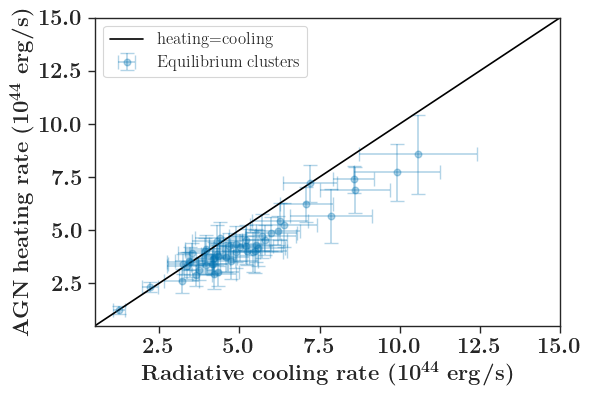

In [70]:
equilibrium_clusters = []
eq_heating_rates = []
eq_cooling_rates = []
for n in nfws_subset:
    h = n.total_heating_rate(0.001*n.R500, n.R500, 0.1*n.R500)
    c = n.total_cooling_rate(0.001*n.R500, n.R500, vol_rate='gfe')
    #print(h.value-c.value, 2*h.plus, 2*h.minus, 2*c.plus, 2*c.minus)
    if (h.value - c.value) <= 2*h.minus or (h.value - c.value) <= 2*c.plus:
        if (h.value-c.value)>= -2*h.plus or (h.value-c.value)>= -2*c.minus:
            equilibrium_clusters.append(n)
            eq_heating_rates.append(h)
            eq_cooling_rates.append(c)
fig = plt.figure()
plt.errorbar(np.divide(eq_cooling_rates,1e44), np.divide(eq_heating_rates,1e44),
             xerr=[[c.minus for c in np.divide(eq_cooling_rates,1e44)],[c.plus for c in np.divide(eq_cooling_rates,1e44)]],
             yerr=[[h.minus for h in np.divide(eq_cooling_rates,1e44)],[h.plus for h in np.divide(eq_cooling_rates,1e44)]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='Equilibrium clusters')

plt.plot([0, 16], [0, 16], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlim(0.5, 15)
plt.ylim(0.5, 15)
plt.legend()
plt.show()

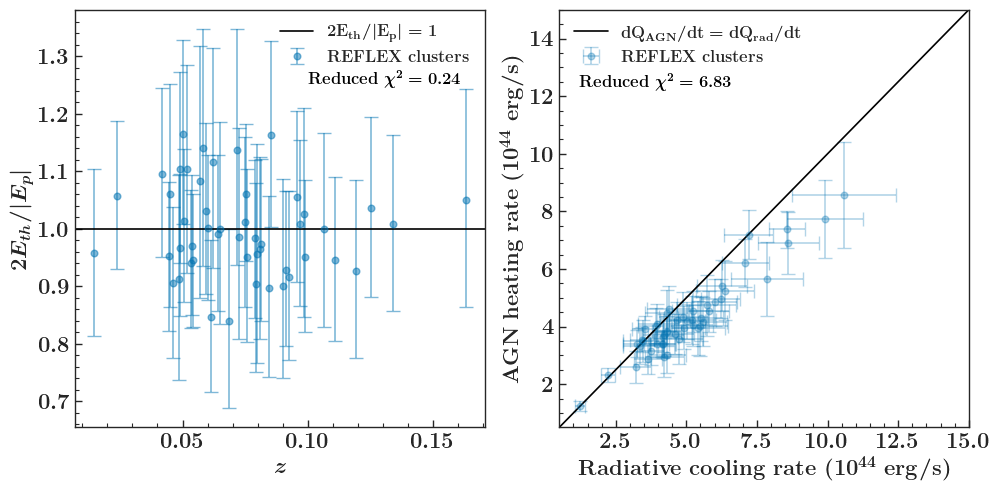

In [84]:
paper_plot()
#mpl.rcParams['text.usetex'] = False

subplotsfig, (ax1, ax2) =  plt.subplots(1, 2, figsize=(10, 5))
zs = [n.z for n in equilibrium_clusters]

# First subplot
ax1.errorbar(zs, eq_vir_frac,
             yerr=[[v.minus for v in eq_vir_frac],[v.plus for v in eq_vir_frac]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label=f'$\mathrm{{REFLEX~clusters}}$')
ax1.axhline(1.0, color='black', label=f'$\mathrm{{2E_{{th}}/|E_{{p}}| = 1}}$')
ax1.legend(frameon=False)
#ax1.set_title('Plot 1')
ax1.set_xlabel(f'$z$', size=16)
ax1.set_ylabel(f'$2E_{{th}}/|E_{{p}}|$', size=16)
ax1.minorticks_on()  # Enable minor ticks
ax1.tick_params(which='both', direction='in')


ax1.text( 0.1, 1.25, f'$\mathrm{{Reduced~}}\chi^2 = {virialization_chi_squared_subset:.2f}$', fontsize=12, color='black')


# Second subplot
ax2.errorbar(np.divide(eq_cooling_rates,1e44), np.divide(eq_heating_rates,1e44),
             xerr=[[c.minus for c in np.divide(eq_cooling_rates,1e44)],[c.plus for c in np.divide(eq_cooling_rates,1e44)]],
             yerr=[[h.minus for h in np.divide(eq_cooling_rates,1e44)],[h.plus for h in np.divide(eq_cooling_rates,1e44)]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label=f'$\mathrm{{REFLEX~clusters}}$')


#plt.scatter(cold_nfw.total_cooling_rate(0.001*cold_nfw.R500, cold_nfw.R500, vol_rate='gfe')/1e44, cold_nfw.total_heating_rate(0.001*cold_nfw.R500, cold_nfw.R500, 0.1*cold_nfw.R500)/1e44, marker='*', s=100)

ax2.plot([0, 16], [0, 16], label='$\mathrm{{dQ_{AGN}}/{dt} = {dQ_{rad}}/{dt}}$', c='k')
plt.xlim(0.5, 15)
plt.ylim(0.5, 15)

ax2.set_ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.set_xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.legend(frameon=False)
ax2.minorticks_on()  # Enable minor ticks
ax2.tick_params(which='both', direction='in')



ax2.text(1.2, 12.3, f'$\mathrm{{Reduced~}}\chi^2 = {equil_chi_squared_subset:.2f}$', fontsize=12, color='black')

#ax2.set_title('Plot 2')



plt.tight_layout()


In [85]:
savefig(subplotsfig,'plots/equilibrium_plots.png') 

2024-10-07T13:20:49.550451: made plots/equilibrium_plots.png


In [67]:
distances = np.abs(np.subtract([c.value for c in cooling_rates/1e44], [h.value for h in heating_rates/1e44]))

In [69]:
max(distances)

7.662470732888506

In [65]:
savefig(subplotsfig,'plots/equilibrium_plots.png') 

2024-08-27T14:59:45.392600: made plots/equilibrium_plots.png


In [17]:
import pickle
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
        comb_data = pickle.load(f)

In [19]:
comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX']['L500']

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_44310/616889684.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX']['L500']


2      0.846881
3      1.809494
6      1.086002
9      1.236332
10     2.827248
         ...   
541    1.852614
543    1.029501
547    1.336537
549    1.629622
550    1.051539
Name: L500, Length: 173, dtype: float64

In [80]:
import pickle

with open('data/equilibrium_clusters.pkl', 'wb') as f:
    pickle.dump(equilibrium_clusters, f)